# Projet : Analyse des habitudes de consommation (Online Retail II – UCI)

- **Partie A** : Clustering des clients (segmentation RFM) – Modules 4 et 5
- **Partie B** : Classification de la probabilité de réachat – Module 3

Données : `online+retail+ii/online_retail_II.xlsx` (2 feuilles, déc. 2009 → déc. 2011).

**Règle anti-fuite** : toute étape qui apprend des données (StandardScaler, sélection des variables, hyperparamètres) est placée dans un `Pipeline` et n'est apprise que sur les données d'entraînement de l'étape ; le jeu de test de la Partie B est mis de côté avant toute sélection.

Voir `rapport_projet.md` pour l'explication détaillée.

## 0. IMPORTATION DES BIBLIOTHÈQUES

In [1]:
# 0. IMPORTATION DES BIBLIOTHÈQUES
# -----------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prétraitement
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Clustering (Modules 4 et 5)
from sklearn.cluster import KMeans, AgglomerativeClustering, BisectingKMeans
from sklearn.cluster import DBSCAN, HDBSCAN, SpectralClustering
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram

# Métriques de clustering (Modules 4 et 5)
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics import calinski_harabasz_score, adjusted_rand_score
from sklearn.metrics import pairwise_distances

# Visualisation (Module 5 : PCA et t-SNE)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Sélection des variables (Module 3)
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import Lasso

# Modèles de classification et ensembles (Module 3)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Validation croisée et évaluation (Module 3)
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score, cross_validate, GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from scipy.stats import wilcoxon

# Dossier où l'on enregistre toutes les figures du rapport
os.makedirs("figures", exist_ok=True)

# Afficher toutes les colonnes des tableaux pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Graine aléatoire fixe pour que les résultats soient reproductibles
SEED = 42

## 1. CHARGEMENT DES DONNÉES (nouveau jeu : online+retail+ii)

In [2]:
# 1. CHARGEMENT DES DONNÉES (nouveau jeu : online+retail+ii)
# -----------------------------------------------------------------------------
# Le fichier Excel contient deux feuilles (une par année). Chaque ligne
# correspond à un produit acheté dans une facture. On lit les deux feuilles
# et on les met bout à bout.
fichier = "online+retail+ii/online_retail_II.xlsx"
annee_1 = pd.read_excel(fichier, sheet_name="Year 2009-2010")
annee_2 = pd.read_excel(fichier, sheet_name="Year 2010-2011")
df = pd.concat([annee_1, annee_2], ignore_index=True)

print("Dimensions du jeu de données brut :", df.shape)
print(df.head())
print("\nValeurs manquantes par colonne :")
print(df.isnull().sum())

Dimensions du jeu de données brut : (1067371, 8)
  Invoice StockCode                          Description  Quantity         InvoiceDate  Price  Customer ID         Country
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12 2009-12-01 07:45:00   6.95      13085.0  United Kingdom
1  489434    79323P                   PINK CHERRY LIGHTS        12 2009-12-01 07:45:00   6.75      13085.0  United Kingdom
2  489434    79323W                  WHITE CHERRY LIGHTS        12 2009-12-01 07:45:00   6.75      13085.0  United Kingdom
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48 2009-12-01 07:45:00   2.10      13085.0  United Kingdom
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24 2009-12-01 07:45:00   1.25      13085.0  United Kingdom

Valeurs manquantes par colonne :
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dty

## 2. NETTOYAGE ET PRÉPARATION DES DONNÉES

In [3]:
# 2. NETTOYAGE ET PRÉPARATION DES DONNÉES
# -----------------------------------------------------------------------------
# 2.1 On supprime les lignes sans identifiant client (impossible de segmenter
#     un client que l'on ne connaît pas).
df = df.dropna(subset=["Customer ID"])
df["Customer ID"] = df["Customer ID"].astype(int)

# 2.2 On supprime les doublons exacts. Les deux feuilles se chevauchent
#     (1er au 9 décembre 2010) : ces lignes en double sont aussi supprimées ici.
df = df.drop_duplicates()

# 2.3 On retire les lignes qui ne sont pas des produits : frais de port,
#     commissions, ajustements manuels, remises, frais bancaires...
codes_non_produits = ["POST", "DOT", "M", "C2", "D", "S", "B", "BANK CHARGES",
                      "ADJUST", "ADJUST2", "AMAZONFEE", "PADS", "CRUK", "TEST001", "TEST002"]
df = df[~df["StockCode"].astype(str).isin(codes_non_produits)]

# 2.4 Les factures dont le numéro commence par "C" sont des annulations.
#     On les met de côté : elles serviront plus tard comme variable (Partie B).
df["Invoice"] = df["Invoice"].astype(str)
annulations = df[df["Invoice"].str.startswith("C")]
df = df[~df["Invoice"].str.startswith("C")]

# 2.5 On garde seulement les quantités et prix strictement positifs.
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]

# 2.6 Création du montant de chaque ligne.
df["TotalPrice"] = df["Quantity"] * df["Price"]

print("\nDimensions après nettoyage :", df.shape)
print("Nombre de clients uniques :", df["Customer ID"].nunique())
print("Période :", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())


Dimensions après nettoyage : (776579, 9)
Nombre de clients uniques : 5852
Période : 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


# PARTIE A : CLUSTERING DES CLIENTS (SEGMENTATION RFM) - MODULES 4 ET 5

## 3. CONSTRUCTION DES VARIABLES RFM


Aperçu du tableau RFM :
             Recence  Frequence   Montant
Customer ID                              
12346            326          3  77352.96
12347              2          8   4921.53
12348             75          5   1658.40
12349             19          3   3678.69
12350            310          1    294.40
           Recence    Frequence        Montant
count  5852.000000  5852.000000    5852.000000
mean    200.198052     6.253247    2916.709282
std     208.509570    12.749286   14306.865864
min       1.000000     1.000000       2.950000
25%      25.000000     1.000000     339.575000
50%      95.000000     3.000000     856.020000
75%     379.000000     7.000000    2241.030000
max     739.000000   373.000000  580987.040000


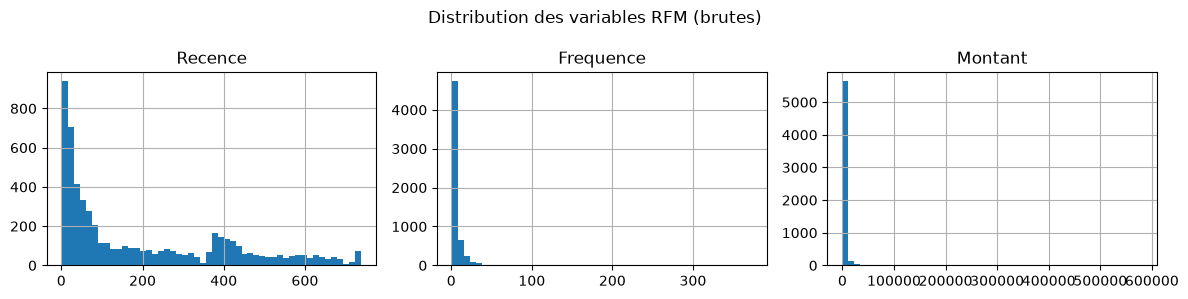

In [4]:
# 3. CONSTRUCTION DES VARIABLES RFM
# -----------------------------------------------------------------------------
# R = Récence   : nombre de jours depuis le dernier achat
# F = Fréquence : nombre de factures différentes
# M = Montant   : somme totale dépensée
# Date de référence = lendemain du dernier achat présent dans les données.
date_reference = df["InvoiceDate"].max() + pd.Timedelta(days=1)

dernier_achat = df.groupby("Customer ID")["InvoiceDate"].max()

rfm = pd.DataFrame()
rfm["Recence"] = (date_reference - dernier_achat).dt.days
rfm["Frequence"] = df.groupby("Customer ID")["Invoice"].nunique()
rfm["Montant"] = df.groupby("Customer ID")["TotalPrice"].sum()

print("\nAperçu du tableau RFM :")
print(rfm.head())
print(rfm.describe())

# Histogrammes : les distributions sont très asymétriques (quelques très gros clients)
rfm.hist(bins=50, figsize=(12, 3), layout=(1, 3))
plt.suptitle("Distribution des variables RFM (brutes)")
plt.tight_layout()
plt.savefig("figures/01_distribution_rfm.png")
plt.show()

## 4. PRÉTRAITEMENT POUR LE CLUSTERING (Module 4 : normalisation, valeurs aberrantes)

In [5]:
# 4. PRÉTRAITEMENT POUR LE CLUSTERING (Module 4 : normalisation, valeurs aberrantes)
# -----------------------------------------------------------------------------
# 4.1 Transformation logarithmique : réduit l'effet des valeurs aberrantes
#     (clients qui dépensent énormément), important car K-Means y est sensible.
#     log1p agit valeur par valeur : il n'apprend rien sur le jeu de données,
#     il ne peut donc pas créer de fuite d'information.
rfm_log = np.log1p(rfm)

# 4.2 Standardisation (moyenne 0, écart-type 1) : indispensable pour K-Means,
#     sinon le Montant (en milliers) dominerait la Récence (en jours).
#     CORRECTION ANTI-FUITE : le StandardScaler n'est PAS appliqué ici sur
#     tout le tableau. Il est placé DANS un Pipeline avec chaque méthode de
#     clustering (sections 5 à 9). Ainsi, à chaque ajustement (y compris sur
#     les échantillons bootstrap du test de stabilité), la moyenne et
#     l'écart-type sont appris uniquement sur les données de cet ajustement.

## 5. K-MEANS : CHOIX DU NOMBRE DE CLUSTERS (Module 4)

k=2 | inertie=8562 | silhouette=0.438 | DB=0.874 | CH=6146


k=3 | inertie=6338 | silhouette=0.347 | DB=1.037 | CH=5177


k=4 | inertie=4908 | silhouette=0.365 | DB=0.931 | CH=5024


k=5 | inertie=4090 | silhouette=0.343 | DB=0.950 | CH=4813


k=6 | inertie=3549 | silhouette=0.335 | DB=0.962 | CH=4614


k=7 | inertie=3182 | silhouette=0.303 | DB=0.984 | CH=4400


k=8 | inertie=2892 | silhouette=0.295 | DB=0.990 | CH=4233


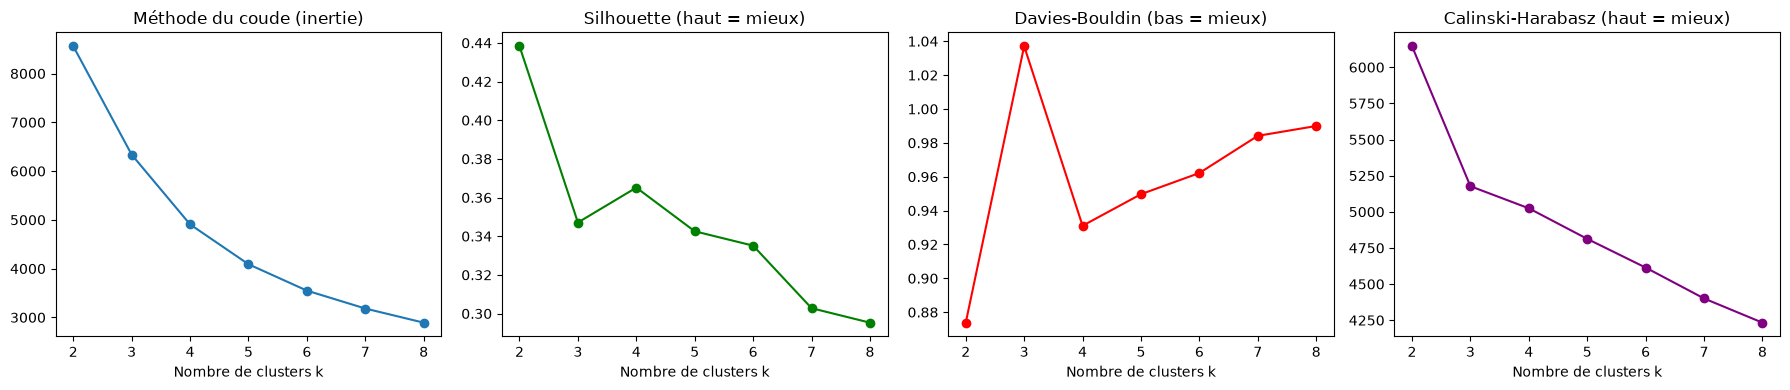

In [6]:
# 5. K-MEANS : CHOIX DU NOMBRE DE CLUSTERS (Module 4)
# -----------------------------------------------------------------------------
# On teste k de 2 à 8 et on calcule : inertie (méthode du coude),
# silhouette (proche de 1 = mieux), Davies-Bouldin (bas = mieux),
# Calinski-Harabasz (haut = mieux, Module 5).
liste_k = range(2, 9)
inerties = []
silhouettes = []
davies = []
calinski = []

for k in liste_k:
    pipeline_k = Pipeline([("scaler", StandardScaler()),
                           ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=SEED))])
    labels = pipeline_k.fit_predict(rfm_log)
    # Les métriques sont mesurées dans l'espace standardisé appris par ce pipeline
    X_k = pipeline_k.named_steps["scaler"].transform(rfm_log)
    inerties.append(pipeline_k.named_steps["kmeans"].inertia_)
    silhouettes.append(silhouette_score(X_k, labels))
    davies.append(davies_bouldin_score(X_k, labels))
    calinski.append(calinski_harabasz_score(X_k, labels))
    print(f"k={k} | inertie={inerties[-1]:.0f} | silhouette={silhouettes[-1]:.3f}"
          f" | DB={davies[-1]:.3f} | CH={calinski[-1]:.0f}")

# Graphiques des 4 critères
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].plot(liste_k, inerties, marker="o")
axes[0].set_title("Méthode du coude (inertie)")
axes[1].plot(liste_k, silhouettes, marker="o", color="green")
axes[1].set_title("Silhouette (haut = mieux)")
axes[2].plot(liste_k, davies, marker="o", color="red")
axes[2].set_title("Davies-Bouldin (bas = mieux)")
axes[3].plot(liste_k, calinski, marker="o", color="purple")
axes[3].set_title("Calinski-Harabasz (haut = mieux)")
for ax in axes:
    ax.set_xlabel("Nombre de clusters k")
plt.tight_layout()
plt.savefig("figures/02_choix_k_kmeans.png")
plt.show()

# Choix de k : compromis entre le coude, les métriques et l'interprétation
# marketing (justification détaillée dans le rapport).
K_CHOISI = 4

kmeans = Pipeline([("scaler", StandardScaler()),
                   ("modele", KMeans(n_clusters=K_CHOISI, n_init=10, random_state=SEED))])
labels_kmeans = kmeans.fit_predict(rfm_log)
rfm["Cluster_KMeans"] = labels_kmeans

# Espace standardisé appris par le pipeline K-Means. Il sert uniquement à
# MESURER et à DESSINER (métriques, dendrogramme, courbe k-distance, PCA,
# t-SNE) : chaque méthode ci-dessous refait sa propre standardisation.
X_rfm = kmeans.named_steps["scaler"].transform(rfm_log)

## 6. CLUSTERING HIÉRARCHIQUE (Module 4)

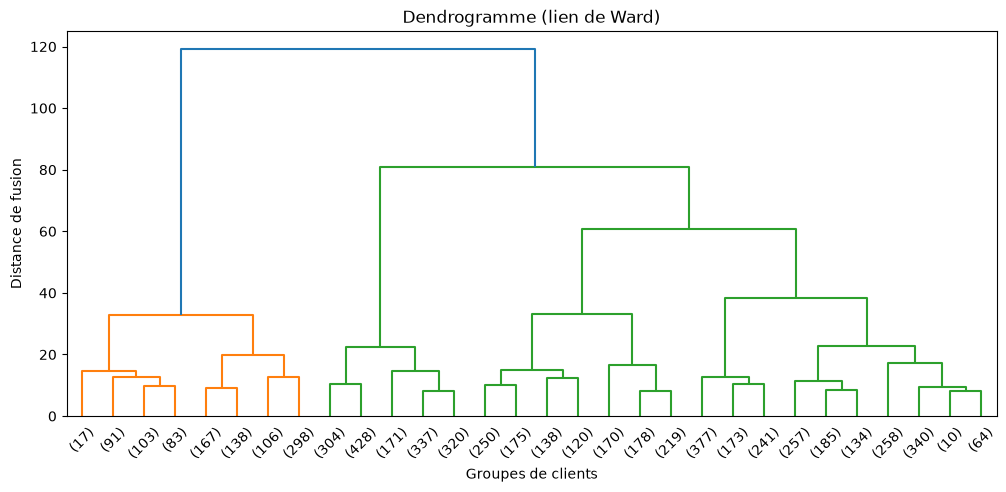

In [7]:
# 6. CLUSTERING HIÉRARCHIQUE (Module 4)
# -----------------------------------------------------------------------------
# 6.1 Dendrogramme (lien de Ward : minimise la variance intra-cluster)
Z = linkage(X_rfm, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30)   # on n'affiche que les 30 dernières fusions
plt.title("Dendrogramme (lien de Ward)")
plt.xlabel("Groupes de clients")
plt.ylabel("Distance de fusion")
plt.savefig("figures/03_dendrogramme.png")
plt.show()

# 6.2 Agglomératif (bottom-up) avec le même nombre de clusters
agglo = Pipeline([("scaler", StandardScaler()),
                  ("modele", AgglomerativeClustering(n_clusters=K_CHOISI, linkage="ward"))])
labels_agglo = agglo.fit_predict(rfm_log)

# 6.3 Divisif (top-down) avec Bisecting K-Means
bisect = Pipeline([("scaler", StandardScaler()),
                   ("modele", BisectingKMeans(n_clusters=K_CHOISI, random_state=SEED))])
labels_bisect = bisect.fit_predict(rfm_log)

## 7. DBSCAN (Modules 4 et 5)

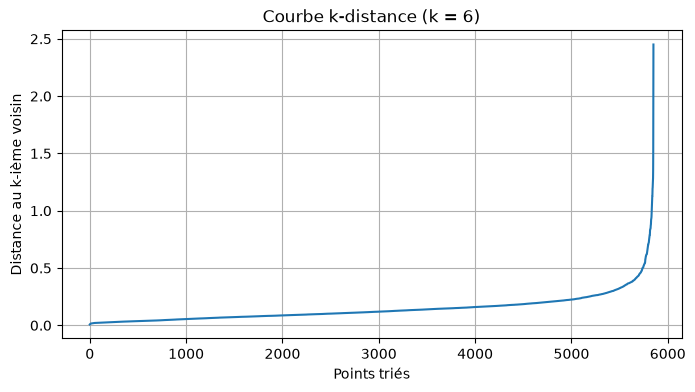


DBSCAN -> nombre de clusters : 3
DBSCAN -> nombre de points de bruit : 167


In [8]:
# 7. DBSCAN (Modules 4 et 5)
# -----------------------------------------------------------------------------
# 7.1 Choix de minPts : règle du cours minPts ≈ 2 x dimension = 2 x 3 = 6
MIN_PTS = 6

# 7.2 Choix de eps : courbe k-distance (distance au k-ième voisin, triée).
#     On repère le "coude" de la courbe.
voisins = NearestNeighbors(n_neighbors=MIN_PTS)
voisins.fit(X_rfm)
distances, indices = voisins.kneighbors(X_rfm)
distances_k = np.sort(distances[:, MIN_PTS - 1])

plt.figure(figsize=(8, 4))
plt.plot(distances_k)
plt.title(f"Courbe k-distance (k = {MIN_PTS})")
plt.xlabel("Points triés")
plt.ylabel("Distance au k-ième voisin")
plt.grid(True)
plt.savefig("figures/04_courbe_k_distance.png")
plt.show()

# Valeur lue au coude de la courbe
EPS = 0.35

dbscan = Pipeline([("scaler", StandardScaler()),
                   ("modele", DBSCAN(eps=EPS, min_samples=MIN_PTS))])
labels_dbscan = dbscan.fit_predict(rfm_log)
print("\nDBSCAN -> nombre de clusters :", len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0))
print("DBSCAN -> nombre de points de bruit :", (labels_dbscan == -1).sum())

## 8. HDBSCAN (Module 5) : version hiérarchique, moins sensible à eps

In [9]:
# 8. HDBSCAN (Module 5) : version hiérarchique, moins sensible à eps
# -----------------------------------------------------------------------------
hdbscan = Pipeline([("scaler", StandardScaler()),
                    ("modele", HDBSCAN(min_cluster_size=50, min_samples=MIN_PTS))])
labels_hdbscan = hdbscan.fit_predict(rfm_log)
print("\nHDBSCAN -> nombre de clusters :", len(set(labels_hdbscan)) - (1 if -1 in labels_hdbscan else 0))
print("HDBSCAN -> nombre de points de bruit :", (labels_hdbscan == -1).sum())


HDBSCAN -> nombre de clusters : 6
HDBSCAN -> nombre de points de bruit : 1080


## 9. CLUSTERING SPECTRAL (Module 5)

In [10]:
# 9. CLUSTERING SPECTRAL (Module 5)
# -----------------------------------------------------------------------------
# Graphe de similarité construit avec les plus proches voisins, puis K-Means
# appliqué sur les vecteurs propres du Laplacien.
spectral = Pipeline([("scaler", StandardScaler()),
                     ("modele", SpectralClustering(n_clusters=K_CHOISI, affinity="nearest_neighbors",
                                                   n_neighbors=15, random_state=SEED))])
labels_spectral = spectral.fit_predict(rfm_log)

## 10. ÉVALUATION AVANCÉE ET COMPARAISON DES MÉTHODES (Modules 4 et 5)

In [11]:
# 10. ÉVALUATION AVANCÉE ET COMPARAISON DES MÉTHODES (Modules 4 et 5)
# -----------------------------------------------------------------------------
# Indice de Dunn (Module 5) = distance minimale entre deux clusters
#                             / diamètre maximal d'un cluster  (haut = mieux)
# Il n'existe pas dans scikit-learn : on le calcule directement avec sa formule.
D = pairwise_distances(X_rfm)   # matrice de toutes les distances entre clients


def indice_dunn(labels):
    clusters = [c for c in np.unique(labels) if c != -1]   # on ignore le bruit
    distance_min_inter = np.inf
    diametre_max = 0
    for i in clusters:
        dans_i = labels == i
        # diamètre du cluster i = plus grande distance entre deux de ses points
        diametre_max = max(diametre_max, D[dans_i][:, dans_i].max())
        for j in clusters:
            if j > i:
                dans_j = labels == j
                # distance entre les clusters i et j = plus petite distance entre leurs points
                distance_min_inter = min(distance_min_inter, D[dans_i][:, dans_j].min())
    return distance_min_inter / diametre_max


# Stabilité (Module 5) : on ré-applique le pipeline complet (standardisation
# + clustering) sur des échantillons bootstrap et on compare (Adjusted Rand
# Index) les nouvelles étiquettes avec les étiquettes initiales.
# Le StandardScaler est ré-appris sur chaque échantillon bootstrap : aucune
# statistique calculée sur le jeu complet n'est réutilisée.
def stabilite(pipeline, labels_initiaux, n_repetitions=10):
    generateur = np.random.RandomState(SEED)
    scores = []
    for r in range(n_repetitions):
        indices_boot = generateur.choice(len(rfm_log), size=len(rfm_log), replace=True)
        # clone = copie "vierge" du pipeline : le pipeline d'origine n'est pas modifié
        nouveaux_labels = clone(pipeline).fit_predict(rfm_log.iloc[indices_boot])
        scores.append(adjusted_rand_score(labels_initiaux[indices_boot], nouveaux_labels))
    return np.mean(scores)


# Liste des méthodes à comparer : (nom, pipeline, étiquettes obtenues)
methodes = [
    ("K-Means", kmeans, labels_kmeans),
    ("Hiérarchique (Ward)", agglo, labels_agglo),
    ("Bisecting K-Means", bisect, labels_bisect),
    ("DBSCAN", dbscan, labels_dbscan),
    ("HDBSCAN", hdbscan, labels_hdbscan),
    ("Spectral", spectral, labels_spectral),
]

resultats_clustering = []
for nom, pipeline, labels in methodes:
    sans_bruit = labels != -1          # les métriques sont calculées sans les points de bruit
    X_ok = X_rfm[sans_bruit]
    labels_ok = labels[sans_bruit]
    nb_clusters = len(np.unique(labels_ok))
    resultats_clustering.append([
        nom,
        nb_clusters,
        (labels == -1).sum(),
        silhouette_score(X_ok, labels_ok),
        davies_bouldin_score(X_ok, labels_ok),
        calinski_harabasz_score(X_ok, labels_ok),
        indice_dunn(labels),
        stabilite(pipeline, labels),
    ])

tableau_clustering = pd.DataFrame(
    resultats_clustering,
    columns=["Méthode", "Nb clusters", "Nb bruit", "Silhouette", "Davies-Bouldin",
             "Calinski-Harabasz", "Dunn", "Stabilité (ARI)"])
print("\n=== Comparaison des méthodes de clustering ===")
print(tableau_clustering.round(3).to_string(index=False))
tableau_clustering.round(3).to_csv("figures/tableau_clustering.csv", index=False)


=== Comparaison des méthodes de clustering ===
            Méthode  Nb clusters  Nb bruit  Silhouette  Davies-Bouldin  Calinski-Harabasz  Dunn  Stabilité (ARI)
            K-Means            4         0       0.365           0.931           5024.147 0.004            0.922
Hiérarchique (Ward)            4         0       0.335           1.001           4451.688 0.006            0.460
  Bisecting K-Means            4         0       0.284           1.220           4328.349 0.002            0.727
             DBSCAN            3       167       0.157           1.743           2479.143 0.057            0.982
            HDBSCAN            6      1080       0.153           2.807           1716.745 0.019            0.735
           Spectral            4         0       0.135           1.292           2072.622 0.001            0.842


## 11. VISUALISATION DES CLUSTERS AVEC PCA ET t-SNE (Module 5)

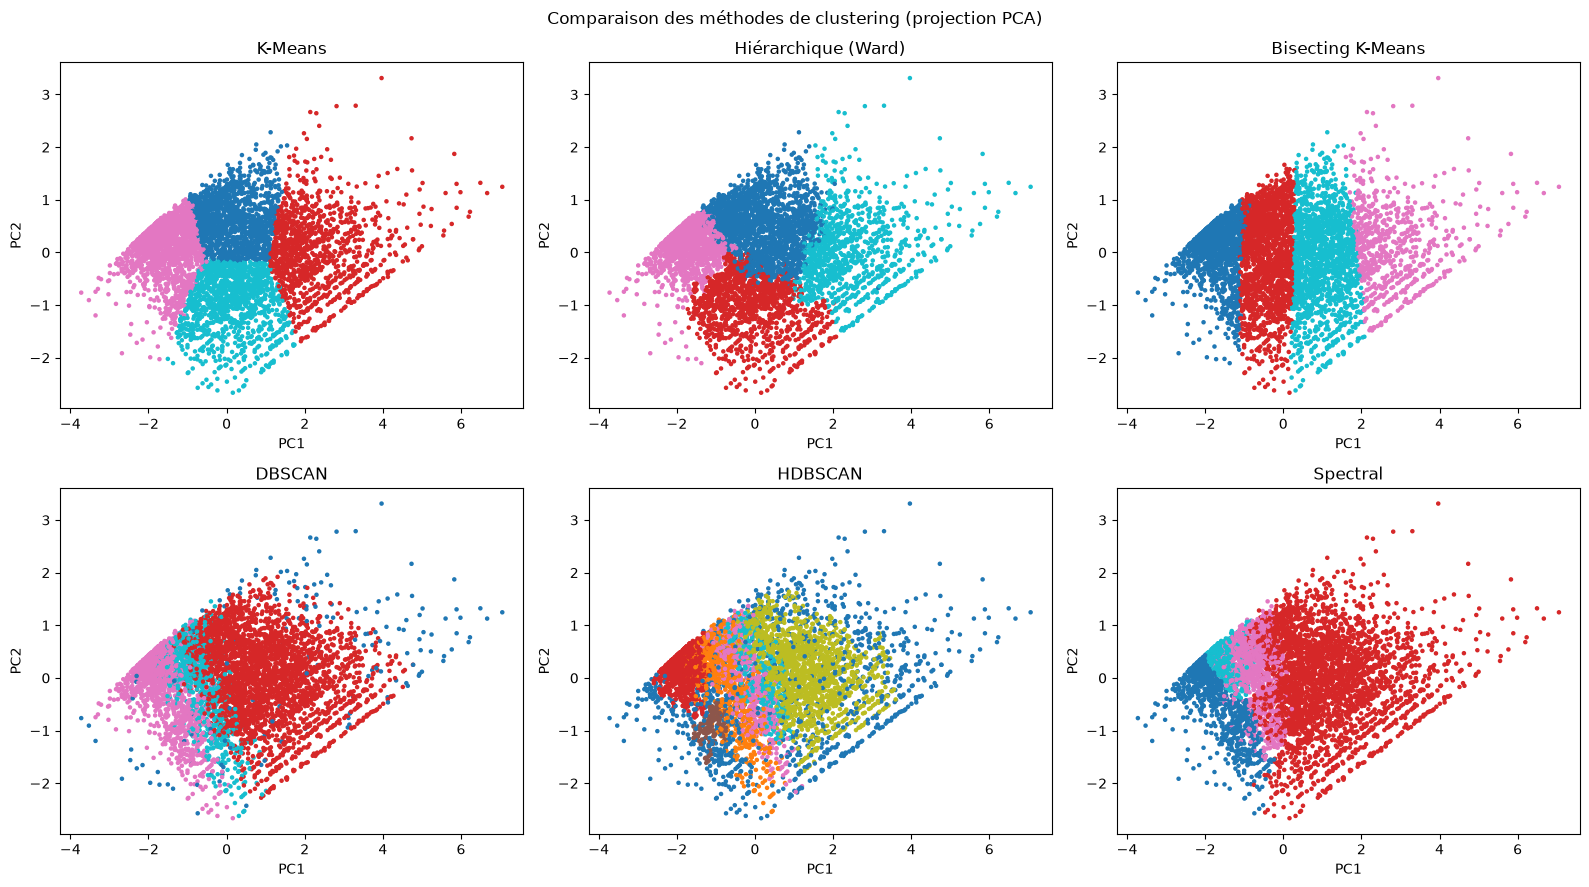

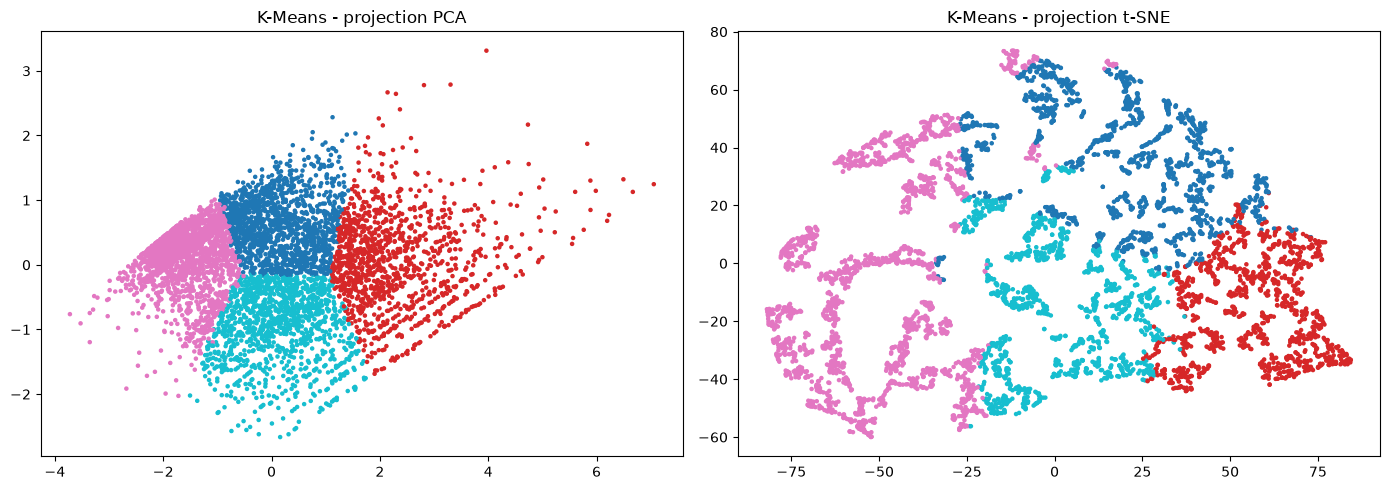

In [12]:
# 11. VISUALISATION DES CLUSTERS AVEC PCA ET t-SNE (Module 5)
# -----------------------------------------------------------------------------
X_pca = PCA(n_components=2, random_state=SEED).fit_transform(X_rfm)
X_tsne = TSNE(n_components=2, random_state=SEED).fit_transform(X_rfm)

# Projection PCA de chaque méthode
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (nom, pipeline, labels) in zip(axes.ravel(), methodes):
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", s=5)
    ax.set_title(nom)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.suptitle("Comparaison des méthodes de clustering (projection PCA)")
plt.tight_layout()
plt.savefig("figures/05_comparaison_pca.png")
plt.show()

# PCA vs t-SNE pour la méthode retenue (K-Means)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_kmeans, cmap="tab10", s=5)
axes[0].set_title("K-Means - projection PCA")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels_kmeans, cmap="tab10", s=5)
axes[1].set_title("K-Means - projection t-SNE")
plt.tight_layout()
plt.savefig("figures/06_kmeans_pca_tsne.png")
plt.show()

## 12. INTERPRÉTATION MÉTIER DES SEGMENTS K-MEANS


=== Profil moyen de chaque segment (K-Means) ===
                Recence  Frequence  Montant  Nb clients
Cluster_KMeans                                         
0                 227.4        5.1   1978.3        1455
1                  27.6       19.2  10590.0        1182
2                 392.6        1.4    317.1        1969
3                  28.2        3.0    841.4        1246


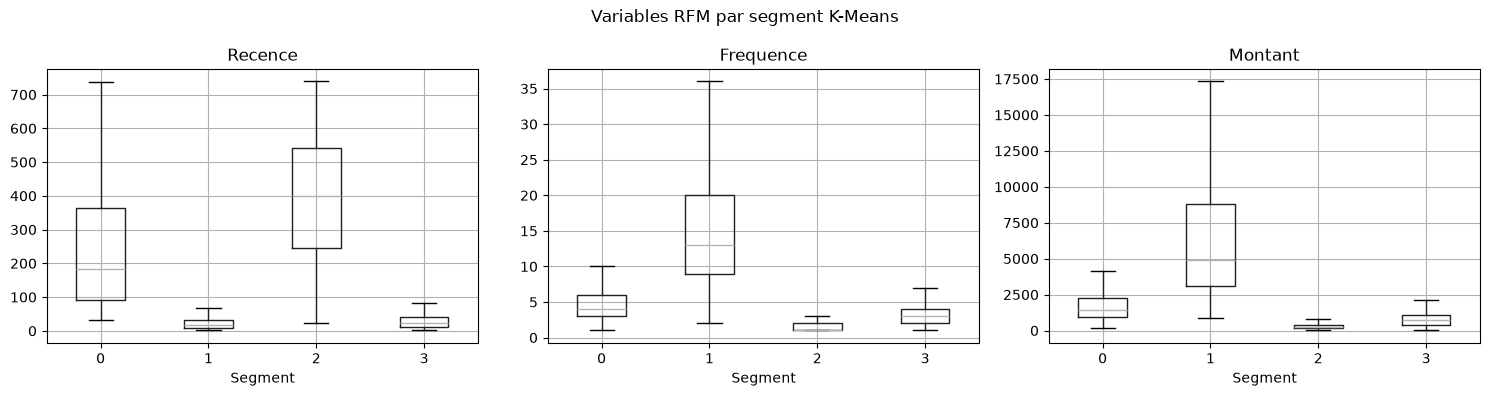

In [13]:
# 12. INTERPRÉTATION MÉTIER DES SEGMENTS K-MEANS
# -----------------------------------------------------------------------------
profil = rfm.groupby("Cluster_KMeans")[["Recence", "Frequence", "Montant"]].mean()
profil["Nb clients"] = rfm["Cluster_KMeans"].value_counts().sort_index()
print("\n=== Profil moyen de chaque segment (K-Means) ===")
print(profil.round(1))
profil.round(1).to_csv("figures/profil_segments.csv")

# Boxplots des variables RFM par segment
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, variable in zip(axes, ["Recence", "Frequence", "Montant"]):
    rfm.boxplot(column=variable, by="Cluster_KMeans", ax=ax, showfliers=False)
    ax.set_title(variable)
    ax.set_xlabel("Segment")
plt.suptitle("Variables RFM par segment K-Means")
plt.tight_layout()
plt.savefig("figures/07_profil_segments.png")
plt.show()

# PARTIE B : CLASSIFICATION DE LA PROBABILITÉ DE RÉACHAT - MODULE 3

## 13. CONSTRUCTION DE LA CIBLE "RÉACHAT" ET SÉPARATION TRAIN / TEST

In [14]:
# 13. CONSTRUCTION DE LA CIBLE "RÉACHAT" ET SÉPARATION TRAIN / TEST
# -----------------------------------------------------------------------------
# On coupe l'historique en deux périodes :
#  - Période d'observation (avant la date de coupure) -> calcul des variables
#  - Période de prédiction (3 derniers mois)          -> la cible
# Cible = 1 si le client a acheté de nouveau pendant les 3 derniers mois.
# Ainsi, aucune information du futur n'est utilisée dans les variables.
# (Les segments de la Partie A ne sont PAS utilisés comme variables : ils sont
#  calculés sur tout l'historique, y compris la période de prédiction.)
date_coupure = pd.Timestamp("2011-09-09")

avant = df[df["InvoiceDate"] < date_coupure]
apres = df[df["InvoiceDate"] >= date_coupure]
annul_avant = annulations[annulations["InvoiceDate"] < date_coupure]

# Variables explicatives calculées sur la période d'observation
clients = pd.DataFrame()
clients["Recence"] = (date_coupure - avant.groupby("Customer ID")["InvoiceDate"].max()).dt.days
clients["Anciennete"] = (date_coupure - avant.groupby("Customer ID")["InvoiceDate"].min()).dt.days
clients["Frequence"] = avant.groupby("Customer ID")["Invoice"].nunique()
clients["Montant"] = avant.groupby("Customer ID")["TotalPrice"].sum()
clients["PanierMoyen"] = clients["Montant"] / clients["Frequence"]
clients["QuantiteTotale"] = avant.groupby("Customer ID")["Quantity"].sum()
clients["NbProduits"] = avant.groupby("Customer ID")["StockCode"].nunique()
clients["PrixMoyen"] = avant.groupby("Customer ID")["Price"].mean()
clients["NbAnnulations"] = annul_avant.groupby("Customer ID")["Invoice"].nunique()
clients["NbAnnulations"] = clients["NbAnnulations"].fillna(0)    # aucun retour = 0
pays = avant.groupby("Customer ID")["Country"].first()
clients["RoyaumeUni"] = (pays == "United Kingdom").astype(int)

# Cible : le client apparaît-il dans la période de prédiction ?
clients["Reachat"] = clients.index.isin(apres["Customer ID"]).astype(int)

print("\nNombre de clients observés :", len(clients))
print("Valeurs manquantes dans le tableau clients :", clients.isnull().sum().sum())
print("Répartition de la cible Reachat :")
print(clients["Reachat"].value_counts(normalize=True).round(3))

X = clients.drop(columns="Reachat")
y = clients["Reachat"]
noms_variables = X.columns

# CORRECTION ANTI-FUITE : on sépare le jeu de test (20 %) AVANT toute
# sélection de variables, standardisation ou comparaison de modèles.
# Les sections 14 à 19 n'utilisent que X_train / y_train. Le jeu de test
# n'est utilisé qu'une seule fois, à la section 20.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Taille du jeu d'entraînement :", X_train.shape, "| taille du jeu de test :", X_test.shape)


Nombre de clients observés : 5253
Valeurs manquantes dans le tableau clients : 0
Répartition de la cible Reachat :
Reachat
0    0.563
1    0.437
Name: proportion, dtype: float64
Taille du jeu d'entraînement : (4202, 10) | taille du jeu de test : (1051, 10)


## 14. SÉLECTION DES VARIABLES - MÉTHODES FILTRES (Module 3, Partie I) (calculées uniquement sur le jeu d'entraînement)


[Filtre] Variance de chaque variable :
Recence           3.041514e+04
Anciennete        3.260705e+04
Frequence         1.160820e+02
Montant           1.691942e+08
PanierMoyen       4.008766e+05
QuantiteTotale    6.858853e+07
NbProduits        1.027632e+04
PrixMoyen         2.469300e+01
NbAnnulations     9.168000e+00
RoyaumeUni        8.100000e-02
dtype: float64
Variables conservées par VarianceThreshold : ['Recence', 'Anciennete', 'Frequence', 'Montant', 'PanierMoyen', 'QuantiteTotale', 'NbProduits', 'PrixMoyen', 'NbAnnulations', 'RoyaumeUni']


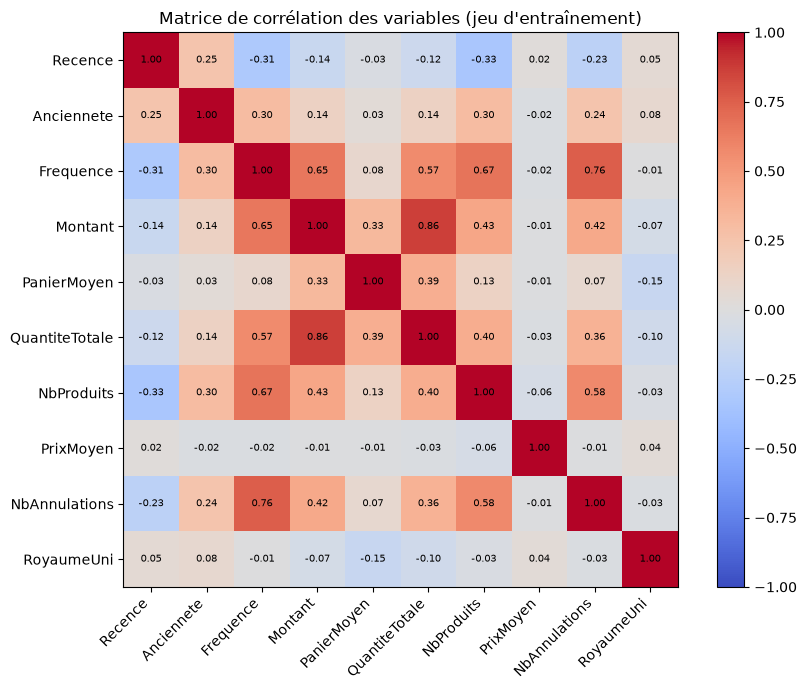


[Filtre] Scores ANOVA (F) et p-values :
                       F  p-value
Recence         962.0047   0.0000
NbProduits      450.5131   0.0000
Frequence       343.0583   0.0000
NbAnnulations   214.8756   0.0000
Montant          77.2040   0.0000
QuantiteTotale   59.2219   0.0000
PrixMoyen        10.5111   0.0012
PanierMoyen       7.2986   0.0069
Anciennete        7.0525   0.0079
RoyaumeUni        2.0563   0.1517
Les 5 meilleures variables (ANOVA) : ['Recence', 'Frequence', 'Montant', 'NbProduits', 'NbAnnulations']

[Filtre] Information mutuelle :
Frequence         0.1157
Recence           0.1059
Montant           0.0979
QuantiteTotale    0.0808
NbProduits        0.0708
NbAnnulations     0.0441
PanierMoyen       0.0244
Anciennete        0.0156
PrixMoyen         0.0031
RoyaumeUni        0.0027
dtype: float64


In [15]:
# 14. SÉLECTION DES VARIABLES - MÉTHODES FILTRES (Module 3, Partie I)
#     (calculées uniquement sur le jeu d'entraînement)
# -----------------------------------------------------------------------------
# 14.1 VarianceThreshold : supprime les variables constantes (variance = 0),
#      exactement comme dans l'exemple du cours.
selecteur_var = VarianceThreshold(threshold=0.0)
selecteur_var.fit(X_train)
print("\n[Filtre] Variance de chaque variable :")
print(X_train.var().round(3))
print("Variables conservées par VarianceThreshold :", list(noms_variables[selecteur_var.get_support()]))

# 14.2 Corrélation : repérer les variables redondantes
correlation = X_train.corr()
plt.figure(figsize=(9, 7))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(noms_variables)), noms_variables, rotation=45, ha="right")
plt.yticks(range(len(noms_variables)), noms_variables)
for i in range(len(noms_variables)):
    for j in range(len(noms_variables)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Matrice de corrélation des variables (jeu d'entraînement)")
plt.tight_layout()
plt.savefig("figures/08_correlation.png")
plt.show()

# 14.3 ANOVA (f_classif) : significativité statistique de chaque variable
selecteur_anova = SelectKBest(score_func=f_classif, k=5)
selecteur_anova.fit(X_train, y_train)
print("\n[Filtre] Scores ANOVA (F) et p-values :")
resultats_anova = pd.DataFrame(index=noms_variables)
resultats_anova["F"] = selecteur_anova.scores_
resultats_anova["p-value"] = selecteur_anova.pvalues_
print(resultats_anova.sort_values("F", ascending=False).round(4))
print("Les 5 meilleures variables (ANOVA) :", list(noms_variables[selecteur_anova.get_support()]))

# 14.4 Information mutuelle : capte aussi les relations non linéaires
info_mutuelle = mutual_info_classif(X_train, y_train, random_state=SEED)
print("\n[Filtre] Information mutuelle :")
print(pd.Series(info_mutuelle, index=noms_variables).sort_values(ascending=False).round(4))

## 15. SÉLECTION DES VARIABLES - MÉTHODES ENVELOPPANTES (Module 3, Partie II)


[Enveloppante] Variables retenues par RFE : ['Recence', 'Frequence', 'NbProduits', 'PrixMoyen', 'NbAnnulations']
Classement RFE (1 = meilleure) :
Recence           1
Frequence         1
NbProduits        1
PrixMoyen         1
NbAnnulations     1
Anciennete        2
QuantiteTotale    3
Montant           4
PanierMoyen       5
RoyaumeUni        6
dtype: int64



[Enveloppante] Nombre optimal de variables (RFECV) : 3
Variables retenues par RFECV : ['Recence', 'Frequence', 'NbProduits']


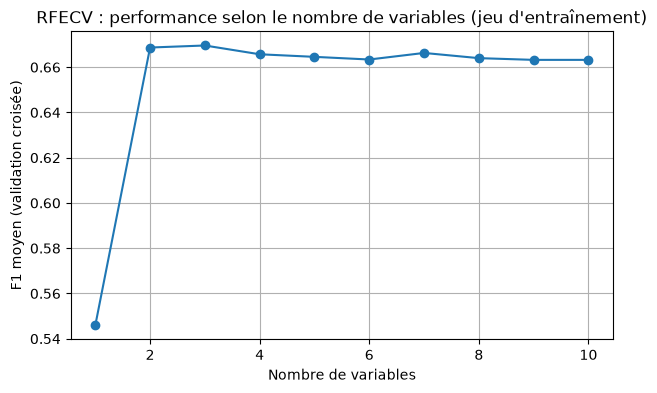

In [16]:
# 15. SÉLECTION DES VARIABLES - MÉTHODES ENVELOPPANTES (Module 3, Partie II)
# -----------------------------------------------------------------------------
# Les modèles linéaires ont besoin de données standardisées.
# CORRECTION ANTI-FUITE : la standardisation est dans un Pipeline, apprise
# sur le jeu d'entraînement seulement (avant : StandardScaler sur tout X).
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# 15.1 RFE : élimine récursivement les variables les moins importantes
pipeline_rfe = Pipeline([("scaler", StandardScaler()),
                         ("selection", RFE(LogisticRegression(max_iter=1000), n_features_to_select=5))])
pipeline_rfe.fit(X_train, y_train)
rfe = pipeline_rfe.named_steps["selection"]
print("\n[Enveloppante] Variables retenues par RFE :", list(noms_variables[rfe.support_]))
print("Classement RFE (1 = meilleure) :")
print(pd.Series(rfe.ranking_, index=noms_variables).sort_values())

# 15.2 RFECV : RFE + validation croisée -> trouve le nombre optimal de variables
pipeline_rfecv = Pipeline([("scaler", StandardScaler()),
                           ("selection", RFECV(LogisticRegression(max_iter=1000), cv=cv_strat, scoring="f1"))])
pipeline_rfecv.fit(X_train, y_train)
rfecv = pipeline_rfecv.named_steps["selection"]
print("\n[Enveloppante] Nombre optimal de variables (RFECV) :", rfecv.n_features_)
print("Variables retenues par RFECV :", list(noms_variables[rfecv.support_]))

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(noms_variables) + 1), rfecv.cv_results_["mean_test_score"], marker="o")
plt.xlabel("Nombre de variables")
plt.ylabel("F1 moyen (validation croisée)")
plt.title("RFECV : performance selon le nombre de variables (jeu d'entraînement)")
plt.grid(True)
plt.savefig("figures/09_rfecv.png")
plt.show()

## 16. SÉLECTION DES VARIABLES - MÉTHODES INTÉGRÉES (Module 3, Partie III)


[Intégrée] Coefficients Lasso :
Recence          -0.1867
Anciennete        0.0329
Frequence         0.0174
Montant          -0.0000
PanierMoyen       0.0000
QuantiteTotale   -0.0000
NbProduits        0.0605
PrixMoyen        -0.0055
NbAnnulations     0.0013
RoyaumeUni       -0.0000
dtype: float64
Variables retenues par Lasso (coef ≠ 0) : ['Recence', 'Anciennete', 'Frequence', 'NbProduits', 'PrixMoyen', 'NbAnnulations']


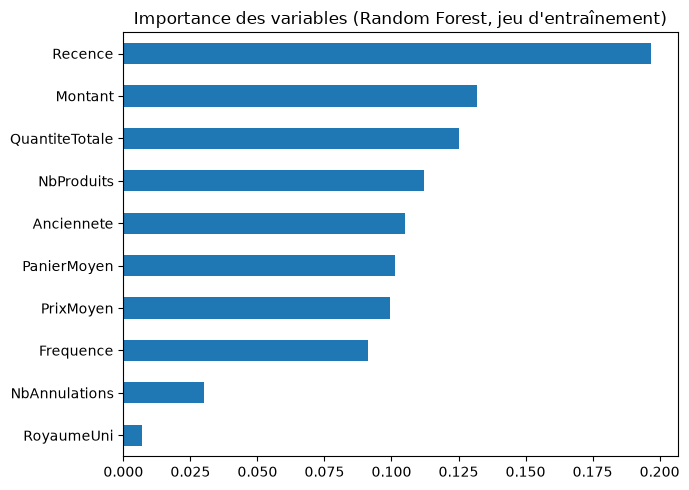

In [17]:
# 16. SÉLECTION DES VARIABLES - MÉTHODES INTÉGRÉES (Module 3, Partie III)
# -----------------------------------------------------------------------------
# 16.1 Lasso (pénalité L1) : met à zéro les coefficients des variables inutiles
pipeline_lasso = Pipeline([("scaler", StandardScaler()), ("lasso", Lasso(alpha=0.01))])
pipeline_lasso.fit(X_train, y_train)
lasso = pipeline_lasso.named_steps["lasso"]
print("\n[Intégrée] Coefficients Lasso :")
print(pd.Series(lasso.coef_, index=noms_variables).round(4))
print("Variables retenues par Lasso (coef ≠ 0) :", list(noms_variables[lasso.coef_ != 0]))

# 16.2 Importances d'arbres (Forêt aléatoire)
foret = RandomForestClassifier(n_estimators=200, random_state=SEED)
foret.fit(X_train, y_train)
importances = pd.Series(foret.feature_importances_, index=noms_variables).sort_values()

plt.figure(figsize=(7, 5))
importances.plot(kind="barh")
plt.title("Importance des variables (Random Forest, jeu d'entraînement)")
plt.tight_layout()
plt.savefig("figures/10_importances_rf.png")
plt.show()

# Les sections 14 à 16 servent à COMPRENDRE les variables.
# Pour l'évaluation des modèles, la sélection (RFECV) est mise DANS le
# Pipeline : elle est ré-apprise sur chaque pli d'entraînement, et le pli de
# validation ne participe jamais au choix des variables.

## 17. COMPARAISON DES MODÈLES PAR VALIDATION CROISÉE (Module 3, Partie IV)


=== Comparaison des modèles (validation croisée 5x3, jeu d'entraînement) ===
               Modèle  Précision  Rappel  F1 moyen  F1 écart-type
Régression logistique      0.690   0.635     0.661          0.016
    Arbre de décision      0.690   0.616     0.649          0.028
        Random Forest      0.646   0.608     0.626          0.028
    Gradient Boosting      0.708   0.617     0.659          0.023


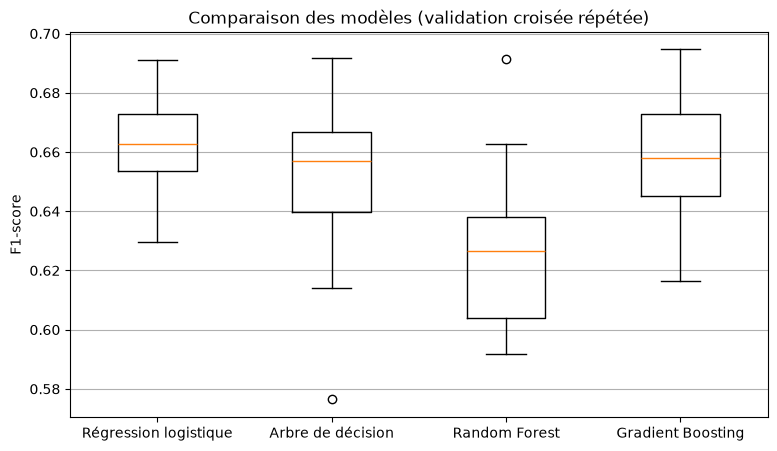

In [18]:
# 17. COMPARAISON DES MODÈLES PAR VALIDATION CROISÉE (Module 3, Partie IV)
# -----------------------------------------------------------------------------
# Pipeline complet = standardisation + sélection RFECV + modèle.
# Validation croisée stratifiée répétée : 5 plis x 3 répétitions = 15 scores,
# ce qui permet de calculer moyenne, écart-type et un test de Wilcoxon fiable.
cv_repetee = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)


def creer_pipeline(modele):
    return Pipeline([("scaler", StandardScaler()),
                     ("selection", RFECV(LogisticRegression(max_iter=1000), cv=cv_strat, scoring="f1")),
                     ("modele", modele)])


modeles = [
    ("Régression logistique", LogisticRegression(max_iter=1000)),
    ("Arbre de décision", DecisionTreeClassifier(max_depth=5, random_state=SEED)),
    ("Random Forest", RandomForestClassifier(n_estimators=200, random_state=SEED)),
    ("Gradient Boosting", GradientBoostingClassifier(random_state=SEED)),
]

noms_modeles = []
scores_f1 = []          # liste des 15 scores F1 de chaque modèle
resultats_modeles = []

for nom, modele in modeles:
    scores = cross_validate(creer_pipeline(modele), X_train, y_train, cv=cv_repetee,
                            scoring=["precision", "recall", "f1"], n_jobs=-1)
    noms_modeles.append(nom)
    scores_f1.append(scores["test_f1"])
    resultats_modeles.append([nom, scores["test_precision"].mean(), scores["test_recall"].mean(),
                              scores["test_f1"].mean(), scores["test_f1"].std()])

tableau_modeles = pd.DataFrame(resultats_modeles,
                               columns=["Modèle", "Précision", "Rappel", "F1 moyen", "F1 écart-type"])
print("\n=== Comparaison des modèles (validation croisée 5x3, jeu d'entraînement) ===")
print(tableau_modeles.round(3).to_string(index=False))
tableau_modeles.round(3).to_csv("figures/tableau_modeles.csv", index=False)

# Visualisation : boxplots des scores F1
plt.figure(figsize=(9, 5))
plt.boxplot(scores_f1, tick_labels=noms_modeles)
plt.ylabel("F1-score")
plt.title("Comparaison des modèles (validation croisée répétée)")
plt.grid(True, axis="y")
plt.savefig("figures/11_boxplot_modeles.png")
plt.show()

## 18. TESTS STATISTIQUES (Module 3) : les différences sont-elles significatives ?

In [19]:
# 18. TESTS STATISTIQUES (Module 3) : les différences sont-elles significatives ?
# -----------------------------------------------------------------------------
# 18.1 Meilleur modèle vs chacun des autres (test de Wilcoxon apparié :
#      les scores sont obtenus sur les mêmes plis).
indice_meilleur = int(np.argmax([s.mean() for s in scores_f1]))
print(f"\nMeilleur modèle (F1 moyen) : {noms_modeles[indice_meilleur]}")
for i in range(len(noms_modeles)):
    if i != indice_meilleur:
        stat, p = wilcoxon(scores_f1[indice_meilleur], scores_f1[i])
        conclusion = "différence significative" if p < 0.05 else "pas de différence significative"
        print(f"  vs {noms_modeles[i]:<22} p-value = {p:.4f} -> {conclusion}")

# 18.2 Impact de la sélection : toutes les variables vs sélection RFECV
#      (même modèle, mêmes plis ; la seule différence est l'étape "selection")
pipeline_sans_selection = Pipeline([("scaler", StandardScaler()), ("modele", modeles[indice_meilleur][1])])
f1_toutes = cross_val_score(pipeline_sans_selection, X_train, y_train, cv=cv_repetee, scoring="f1", n_jobs=-1)
f1_selection = scores_f1[indice_meilleur]
stat, p = wilcoxon(f1_toutes, f1_selection)
print(f"\nToutes les variables ({X.shape[1]})  : F1 = {f1_toutes.mean():.3f} ± {f1_toutes.std():.3f}")
print(f"Avec sélection RFECV : F1 = {f1_selection.mean():.3f} ± {f1_selection.std():.3f}")
print(f"Test de Wilcoxon : p-value = {p:.4f}")


Meilleur modèle (F1 moyen) : Régression logistique
  vs Arbre de décision      p-value = 0.1354 -> pas de différence significative
  vs Random Forest          p-value = 0.0009 -> différence significative
  vs Gradient Boosting      p-value = 0.2078 -> pas de différence significative

Toutes les variables (10)  : F1 = 0.665 ± 0.015
Avec sélection RFECV : F1 = 0.661 ± 0.016
Test de Wilcoxon : p-value = 0.0330


## 19. OPTIMISATION DES MÉTHODES D'ENSEMBLES - CV IMBRIQUÉE (Module 3)

In [20]:
# 19. OPTIMISATION DES MÉTHODES D'ENSEMBLES - CV IMBRIQUÉE (Module 3)
# -----------------------------------------------------------------------------
# Boucle interne : GridSearchCV choisit les meilleurs hyperparamètres.
# Boucle externe : cross_val_score mesure la performance réelle du modèle
# optimisé, sans biais (les plis externes n'ont jamais servi au tuning ni à
# la sélection des variables, qui est dans le pipeline).
cv_interne = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_externe = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Random Forest
pipeline_rf = creer_pipeline(RandomForestClassifier(random_state=SEED))
grille_rf = {"modele__n_estimators": [100, 300],
             "modele__max_depth": [5, 10, None],
             "modele__min_samples_leaf": [1, 5]}
recherche_rf = GridSearchCV(pipeline_rf, grille_rf, cv=cv_interne, scoring="f1", n_jobs=-1)
f1_rf_imbrique = cross_val_score(recherche_rf, X_train, y_train, cv=cv_externe, scoring="f1")

# Gradient Boosting
pipeline_gb = creer_pipeline(GradientBoostingClassifier(random_state=SEED))
grille_gb = {"modele__n_estimators": [100, 200],
             "modele__learning_rate": [0.05, 0.1],
             "modele__max_depth": [2, 3]}
recherche_gb = GridSearchCV(pipeline_gb, grille_gb, cv=cv_interne, scoring="f1", n_jobs=-1)
f1_gb_imbrique = cross_val_score(recherche_gb, X_train, y_train, cv=cv_externe, scoring="f1")

print("\n=== CV imbriquée (ensembles optimisés, jeu d'entraînement) ===")
print(f"Random Forest optimisé     : F1 = {f1_rf_imbrique.mean():.3f} ± {f1_rf_imbrique.std():.3f}")
print(f"Gradient Boosting optimisé : F1 = {f1_gb_imbrique.mean():.3f} ± {f1_gb_imbrique.std():.3f}")


=== CV imbriquée (ensembles optimisés, jeu d'entraînement) ===
Random Forest optimisé     : F1 = 0.661 ± 0.032
Gradient Boosting optimisé : F1 = 0.657 ± 0.023


## 20. MODÈLE FINAL : ÉVALUATION SUR LE JEU DE TEST ET PROBABILITÉS DE RÉACHAT


Modèle final : Random Forest
Meilleurs hyperparamètres : {'modele__max_depth': 5, 'modele__min_samples_leaf': 5, 'modele__n_estimators': 300}
Variables retenues par le modèle final : ['Recence', 'Frequence', 'NbProduits']

Rapport de classification (jeu de test) :
                precision    recall  f1-score   support

Pas de réachat       0.75      0.78      0.77       592
       Réachat       0.70      0.66      0.68       459

      accuracy                           0.73      1051
     macro avg       0.73      0.72      0.73      1051
  weighted avg       0.73      0.73      0.73      1051



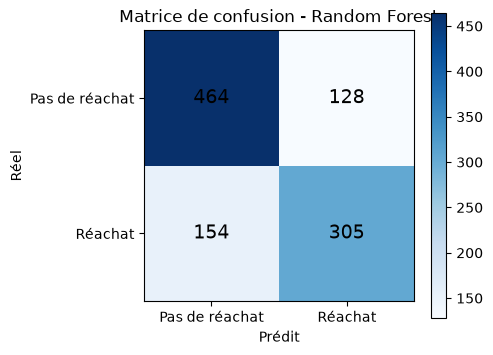


Clients du jeu de test avec la plus forte probabilité de réachat :
             Recence  Anciennete  Frequence    Montant  PanierMoyen  QuantiteTotale  NbProduits  PrixMoyen  NbAnnulations  RoyaumeUni  Proba_reachat  Reachat_reel
Customer ID                                                                                                                                                       
14527              6         645        106   23965.39   226.088585            5885         560   5.146891           19.0           1          0.962             1
12748              1         643        246   30708.00   124.829268           20510        1823   2.542926           17.0           1          0.961             1
14606              1         644        162   27081.51   167.169815           13859        1218   2.834873           58.0           1          0.961             1
17677              8         631         44   30379.58   690.445000           18194         303   2.694130           

In [21]:
# 20. MODÈLE FINAL : ÉVALUATION SUR LE JEU DE TEST ET PROBABILITÉS DE RÉACHAT
# -----------------------------------------------------------------------------
# On garde le meilleur ensemble optimisé, on l'entraîne sur le jeu
# d'entraînement (80 %) et on l'évalue UNE SEULE FOIS sur le jeu de test
# (20 %), mis de côté depuis la section 13.
if f1_gb_imbrique.mean() >= f1_rf_imbrique.mean():
    recherche_finale = recherche_gb
    nom_final = "Gradient Boosting"
else:
    recherche_finale = recherche_rf
    nom_final = "Random Forest"

recherche_finale.fit(X_train, y_train)
print(f"\nModèle final : {nom_final}")
print("Meilleurs hyperparamètres :", recherche_finale.best_params_)
selection_finale = recherche_finale.best_estimator_.named_steps["selection"]
print("Variables retenues par le modèle final :", list(noms_variables[selection_finale.support_]))

y_pred = recherche_finale.predict(X_test)
print("\nRapport de classification (jeu de test) :")
print(classification_report(y_test, y_pred, target_names=["Pas de réachat", "Réachat"]))

matrice = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
plt.imshow(matrice, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, matrice[i, j], ha="center", va="center", fontsize=14)
plt.xticks([0, 1], ["Pas de réachat", "Réachat"])
plt.yticks([0, 1], ["Pas de réachat", "Réachat"])
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title(f"Matrice de confusion - {nom_final}")
plt.colorbar()
plt.tight_layout()
plt.savefig("figures/12_matrice_confusion.png")
plt.show()

# Probabilité de réachat de chaque client du jeu de test
probabilites = recherche_finale.predict_proba(X_test)[:, 1]
resultat_test = X_test.copy()
resultat_test["Proba_reachat"] = probabilites.round(3)
resultat_test["Reachat_reel"] = y_test
print("\nClients du jeu de test avec la plus forte probabilité de réachat :")
print(resultat_test.sort_values("Proba_reachat", ascending=False).head(10))
print("\nClients du jeu de test avec la plus faible probabilité de réachat :")
print(resultat_test.sort_values("Proba_reachat").head(10))

print("\nFIN DU PROGRAMME - figures enregistrées dans le dossier 'figures/'")